# 05 · Exploración de pedidos · Objetivo 2 (predecir el tiempo de preparación)

## ¿Qué queremos conseguir?
Cuando entra un pedido en la cocina, queremos **estimar cuántos minutos tardará en estar listo** (`tiempo_prep_minutos`). Con esa estimación se puede avisar al cliente, organizar mejor a los cocineros o detectar a tiempo los momentos en los que la cocina se satura.

Esto es una **regresión** y es un tipo de **aprendizaje supervisado**:
- **Supervisado** significa que tenemos **ejemplos con la respuesta correcta**: más de 100.000 pedidos pasados en los que sabemos cuánto se tardó en realidad. El modelo aprende de ellos a acertar la respuesta en pedidos nuevos.
- **Regresión** significa que la respuesta es **un número** (minutos), no una etiqueta como "grupo 1" o "grupo 2". (En el objetivo 1 agrupábamos platos sin ninguna respuesta correcta: eso era *no supervisado*.)

Dos palabras que usaremos todo el rato:
- **Variable objetivo** (la "y"): lo que queremos predecir → `tiempo_prep_minutos`.
- **Variables explicativas** (las "X", o *features*): lo que sabemos del pedido y que puede ayudar a predecirlo (cuántos platos lleva, cuánta cola hay en cocina, cuántos cocineros hay…).

## ¿Qué hace este notebook?
Antes de entrenar ningún modelo hay que **mirar bien los datos**. Un modelo nunca avisa de que algo esté raro: aprende lo que le des, aunque sea engañoso. Aquí respondemos a estas preguntas:
1. ¿Los datos están completos y son coherentes?
2. ¿Cómo es la variable que queremos predecir? ¿Hay valores raros?
3. ¿Cómo es cada variable explicativa?
4. ¿Cuáles se relacionan con el tiempo de preparación, y **cómo** (en línea recta, en curva, a saltos)?
5. ¿Cambia el tiempo con la hora, el día o el mes?
6. ¿Hay variables que cuentan lo mismo, o que se combinan entre sí?
7. ¿Cómo debemos separar datos de entrenamiento y de prueba, y qué resultado habría que superar como mínimo?

**No se limpia nada** aquí (eso se hizo en el notebook 02): solo se mira, se comprueba y se anotan las decisiones para el siguiente notebook. **No entrenamos ningún modelo** todavía; solo calculamos una *línea base* muy simple para saber qué hay que mejorar.

**Qué entrega:** ninguna tabla nueva. La entrega son las **conclusiones** (sección 10), que dicen qué variables usar (las que ya tenemos, sin crear ninguna nueva) y cómo evaluar el modelo.

**Cómo ejecutarlo:** *Kernel → Restart & Run All*. Las celdas funcionan de arriba abajo sin tocar nada.

**Índice**
- Guía rápida de conceptos
- 0. Configuración y funciones
- 1. Carga y validación
- 2. La variable objetivo: `tiempo_prep_minutos`
- 3. Variables numéricas del pedido
- 4. Variables de tipo categoría
- 5. Relación de cada variable con el tiempo de preparación
- 6. El tiempo: hora, día de la semana y evolución
- 7. Relaciones entre las propias variables
- 8. Pedidos en cola y cocineros
- 9. Separar entrenamiento y prueba, y línea base
- 10. Conclusiones

---
## Guía rápida de conceptos

Estas palabras aparecen en todo el notebook. Si alguna se olvida, se puede volver aquí.

| Concepto | Qué significa, en sencillo |
|---|---|
| **Variable objetivo (y)** | Lo que queremos predecir: el tiempo de preparación, en minutos. |
| **Variable explicativa (X, *feature*)** | Un dato del pedido que puede ayudar a predecir la variable objetivo. |
| **Regresión** | Predecir un **número** a partir de otros datos. |
| **Histograma** | Gráfico de barras que muestra **cómo se reparten los valores** de una variable. El eje x son los valores (por tramos) y el eje y, cuántos pedidos caen en cada tramo. |
| **Diagrama de caja (*boxplot*)** | Resume una variable en una caja: la **línea central** es la mediana, la **caja** contiene la mitad central de los datos (del cuartil 1 al 3) y los **bigotes** llegan hasta los valores normales más lejanos. Los puntos sueltos son valores atípicos. |
| **Media y mediana** | La **media** suma todos los valores y divide entre cuántos son. La **mediana** es el valor del medio al ordenarlos. Si son muy distintas, hay valores extremos que tiran de la media. |
| **Valor atípico** | Valor muy alejado del resto. Lo detectamos con la **regla del IQR**: el *IQR* es el tramo donde está la mitad central de los datos; se marca como atípico lo que queda a más de 1,5 veces ese tramo por encima o por debajo. |
| **Asimetría** | Si el histograma está equilibrado (≈ 0) o tiene una **cola larga** hacia un lado. Un número positivo significa cola larga hacia los valores grandes. |
| **Correlación (r)** | Número de −1 a 1 que dice si dos variables **se mueven juntas en línea recta**. Cerca de 1: cuando una sube, la otra también. Cerca de −1: una sube y la otra baja. Cerca de 0: no hay relación **en línea recta** (puede haberla en curva). Ojo: que se muevan juntas no significa que una *cause* la otra. |
| **Variable categórica** | Una columna con unas pocas opciones de texto (canal: mesa, delivery, takeaway). Los modelos no entienden texto, así que luego se transforma en números (*codificación*). |
| **Variables redundantes** | Dos variables que cuentan casi lo mismo. Usar las dos no aporta información nueva y puede confundir a algunos modelos. |
| **Interacción** | Cuando el efecto de una variable **depende de otra**. Ejemplo: 10 pedidos en cola es poco con 7 cocineros, pero mucho con 2. |
| **Fuga de información (*data leakage*)** | Dar al modelo un dato que **no se conocería en el momento real de predecir** (o que contiene la respuesta). El modelo parece buenísimo en las pruebas y falla en la vida real. |
| **Entrenamiento y prueba (*train / test*)** | Se separan los datos en dos partes: con la primera el modelo **aprende**; con la segunda se le **examina** con pedidos que no ha visto. Así sabemos si de verdad predice bien. |
| **Línea base** | El resultado de la predicción más simple posible (por ejemplo, decir siempre "25 minutos"). Cualquier modelo serio tiene que **ganarle**. |
| **MAE y RMSE** | Formas de medir el error de las predicciones, **en minutos**. El **MAE** es la media de cuántos minutos nos equivocamos. El **RMSE** hace lo mismo pero castiga más los fallos grandes. |
| **R²** | Cuánta parte de las variaciones del tiempo explica el modelo: 0 = nada (igual que decir siempre la media), 1 = todo. |

---
## 0. Configuración y funciones

**Configuración:** todo lo que se puede cambiar (rutas, umbrales, listas de columnas, colores) está **en una sola celda**. Así, si hay que cambiar algo, se cambia en un único sitio.

**Funciones:** son "recetas" que se escriben una vez y se usan muchas veces (por ejemplo, dibujar un histograma). Evitan copiar y pegar el mismo código y hacen que cada paso tenga un nombre claro. Cada función lleva debajo, entre comillas, una descripción de lo que hace.

In [1]:
from __future__ import annotations   # permite usar list[str] o float | None en versiones antiguas de Python

import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# ---------- Rutas: los datos están en HDFS (el "disco" del proyecto), accesibles por WebHDFS ----------
# Las variables de entorno las pone el contenedor de Docker; si no existen, se usan los valores por defecto.
HOST = os.environ.get("HDFS_WEBHDFS_URL", "http://namenode:9870").replace("http://", "")
OPT = {"user": os.environ.get("HDFS_USER", "root")}          # usuario con el que se accede a HDFS
CLEAN = f"webhdfs://{HOST}/datalake/clean"                    # carpeta de datos ya limpios
RUTA_PEDIDOS = f"{CLEAN}/pedidos_tiempos_preparacion/pedidos_limpio.parquet"   # ENTRADA: la deja el notebook 02

# ---------- Parámetros del análisis ----------
OBJETIVO = "tiempo_prep_minutos"   # la variable que queremos predecir
UMBRAL_IQR = 1.5                   # un valor es atípico si queda a más de 1,5 veces el IQR de los cuartiles
FORMATO_FECHA = "%d-%m-%Y"         # las fechas vienen como texto "día-mes-año"
TIEMPO_MIN, TIEMPO_MAX = 3, 60     # rango de tiempos válido que dejó el notebook 02
FRACCION_ENTRENAMIENTO = 0.80      # el 80 % más antiguo de los pedidos para entrenar, el 20 % más reciente para probar
MIN_PEDIDOS_CELDA = 30             # en las tablas de colores, ocultamos combinaciones con menos pedidos que esto (poco fiables)
N_PEDIDOS_ESPERADOS = 112_963      # filas que deja el notebook 02

# Columnas agrupadas por tipo, para tratarlas juntas
COLS_NUMERICAS = ["n_platos", "num_platos_complejos", "complejidad_pedido", "cola_pedidos",
                  "cocineros_disponibles", "precipitacion_mm", "hora_dec"]
COLS_CATEGORICAS = ["canal", "prioridad_aux", "ingrediente_agotado", "dia_semana"]
COLS_EXPLICATIVAS = COLS_NUMERICAS + COLS_CATEGORICAS

# Nombre largo de cada variable (con unidades), para que los gráficos se entiendan solos
ETIQUETAS = {
    "tiempo_prep_minutos": "tiempo de preparación (minutos)",
    "n_platos": "nº de platos del pedido",
    "num_platos_complejos": "nº de platos complejos",
    "complejidad_pedido": "complejidad del pedido (puntos)",
    "cola_pedidos": "pedidos en cola de cocina",
    "cocineros_disponibles": "cocineros disponibles",
    "precipitacion_mm": "lluvia (mm)",
    "hora_dec": "hora del día (20,5 = 20:30)",
    "canal": "canal del pedido",
    "prioridad_aux": "prioridad del pedido",
    "ingrediente_agotado": "ingrediente agotado (0 = no, 1 = sí)",
    "dia_semana": "día de la semana (1 = lunes … 7 = domingo)",
}

# ---------- Colores de Smart-Restaurant ----------
AZUL = "#1F3A44"          # azul petróleo
NARANJA = "#F28C38"
GRIS_AZULADO = "#5C808E"
MELOCOTON = "#FFE0C2"
CMAP_DIV = LinearSegmentedColormap.from_list("sr_div", [AZUL, "#FFFFFF", NARANJA])        # azul → blanco → naranja
CMAP_SEC = LinearSegmentedColormap.from_list("sr_sec", ["#FFFFFF", MELOCOTON, NARANJA, AZUL])  # de pocos a muchos minutos

# Estilo general de los gráficos
sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "axes.edgecolor": GRIS_AZULADO, "axes.labelcolor": AZUL, "text.color": AZUL})
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")   # los números se muestran con 3 decimales

In [2]:
def validar(condicion: bool, mensaje: str) -> None:
    """Comprueba algo que DEBE cumplirse. Si falla, el notebook se detiene con un mensaje claro."""
    if not condicion:
        raise AssertionError(f"FALLO · {mensaje}")
    print(f"OK · {mensaje}")


def limites_iqr(serie: pd.Series, k: float = UMBRAL_IQR) -> tuple[float, float]:
    """Calcula los dos límites de la regla del IQR: por debajo del inferior o por encima del superior = atípico.

    IQR = distancia entre el cuartil 1 (el 25 % de los datos queda por debajo) y el cuartil 3 (el 75 %).
    Es decir, el tramo donde está la mitad central de los datos.
    """
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


def contar_atipicos(serie: pd.Series, k: float = UMBRAL_IQR) -> int:
    """Cuenta cuántos valores quedan fuera de los límites del IQR (valores atípicos)."""
    bajo, alto = limites_iqr(serie, k)
    return int(((serie < bajo) | (serie > alto)).sum())


def resumen_numerico(df: pd.DataFrame, columnas: list[str]) -> pd.DataFrame:
    """Tabla resumen de cada variable: describe() de pandas + asimetría + nº y % de atípicos.

    Una fila por variable. Columnas: count (cuántos valores), mean (media), std (desviación típica),
    min, 25 %, 50 % (la mediana), 75 %, max, asimetría, atípicos y % de atípicos.
    """
    resumen = df[columnas].astype(float).describe().T
    resumen["asimetria"] = df[columnas].astype(float).skew()
    resumen["atipicos"] = [contar_atipicos(df[c].astype(float)) for c in columnas]
    resumen["% atipicos"] = resumen["atipicos"] / len(df) * 100
    return resumen


def histogramas(df: pd.DataFrame, columnas: list[str], n_columnas: int = 3, bins: int = 30,
                etiqueta_y: str = "nº de pedidos") -> None:
    """Dibuja un histograma por variable: eje x = valor de la variable, eje y = cuántos pedidos caen en cada tramo.

    `bins` es el número de barras. Si la variable tiene pocos valores distintos (por ejemplo 1, 2, 3…),
    dibuja una barra por valor en lugar de agrupar por tramos.
    """
    n_filas = int(np.ceil(len(columnas) / n_columnas))
    fig, axes = plt.subplots(n_filas, n_columnas, figsize=(4.3 * n_columnas, 3.1 * n_filas))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, columnas):
        datos = df[col].astype(float)
        discreta = datos.nunique() <= 25
        sns.histplot(datos, bins=None if discreta else bins, discrete=discreta, color=AZUL, ax=ax)
        ax.set_title(col)
        ax.set_xlabel(ETIQUETAS.get(col, col))
        ax.set_ylabel(etiqueta_y)
    for ax in axes[len(columnas):]:
        ax.set_visible(False)             # esconde los huecos si sobran ejes
    fig.tight_layout()
    plt.show()


def barras_conteo(df: pd.DataFrame, columnas: list[str]) -> None:
    """Dibuja, para cada columna de categorías, cuántos pedidos hay de cada opción (eje y) frente a la opción (eje x)."""
    fig, axes = plt.subplots(1, len(columnas), figsize=(4.0 * len(columnas), 3.1))
    for ax, col in zip(np.atleast_1d(axes), columnas):
        conteo = df[col].value_counts().sort_index()
        sns.barplot(x=conteo.index.astype(str), y=conteo.values, color=AZUL, ax=ax)
        ax.set_title(f"Pedidos por {col}")
        ax.set_xlabel(ETIQUETAS.get(col, col))
        ax.set_ylabel("nº de pedidos")
    fig.tight_layout()
    plt.show()


def tabla_por_grupo(df: pd.DataFrame, columna: str, objetivo: str = OBJETIVO) -> pd.DataFrame:
    """Para cada valor de `columna`: nº de pedidos, tiempo medio, mediana y desviación típica del tiempo de preparación."""
    tabla = df.groupby(columna, observed=True)[objetivo].agg(["count", "mean", "median", "std"])
    tabla.columns = ["pedidos", "tiempo_medio", "tiempo_mediana", "desviacion"]
    return tabla


def barras_tiempo_medio(df: pd.DataFrame, columnas: list[str], objetivo: str = OBJETIVO) -> None:
    """Una gráfica de barras por columna: eje x = opción, eje y = tiempo de preparación medio de esos pedidos.

    El número sobre cada barra es el tiempo medio. Las líneas negras finas son la incertidumbre de la media:
    si son diminutas es porque hay muchos pedidos y la media es fiable.
    """
    fig, axes = plt.subplots(1, len(columnas), figsize=(4.0 * len(columnas), 3.4), sharey=True)
    for ax, col in zip(np.atleast_1d(axes), columnas):
        sns.barplot(data=df, x=col, y=objetivo, color=AZUL, errorbar=("se", 2), ax=ax)
        for barra in ax.patches:
            ax.annotate(f"{barra.get_height():.1f}", (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                        ha="center", va="bottom", fontsize=8, color=AZUL)
        ax.set_title(f"Tiempo medio según {col}")
        ax.set_xlabel(ETIQUETAS.get(col, col))
        ax.set_ylabel(ETIQUETAS[objetivo])
    fig.tight_layout()
    plt.show()


def cajas_tiempo(df: pd.DataFrame, columnas: list[str], objetivo: str = OBJETIVO) -> None:
    """Un diagrama de caja por columna: eje x = opción, eje y = tiempo de preparación.

    Muestra no solo la media sino **cómo se reparten** los tiempos dentro de cada opción.
    """
    fig, axes = plt.subplots(1, len(columnas), figsize=(4.0 * len(columnas), 3.6), sharey=True)
    for ax, col in zip(np.atleast_1d(axes), columnas):
        sns.boxplot(data=df, x=col, y=objetivo, color=MELOCOTON, fliersize=1, linewidth=0.8, ax=ax)
        ax.set_title(f"Tiempos según {col}")
        ax.set_xlabel(ETIQUETAS.get(col, col))
        ax.set_ylabel(ETIQUETAS[objetivo])
    fig.tight_layout()
    plt.show()


def curva_tiempo_medio(df: pd.DataFrame, columnas: list[str], tramos: int = 12, n_columnas: int = 3,
                       objetivo: str = OBJETIVO) -> None:
    """Curva "tiempo medio según el valor de la variable": eje x = valor de la variable, eje y = minutos.

    - La **línea** es el tiempo medio de los pedidos con ese valor.
    - La **banda naranja clara** contiene la mitad central de los pedidos (del cuartil 1 al 3): enseña cuánto se dispersan.
    - Si la variable tiene muchos valores distintos, se agrupan en `tramos` de igual cantidad de pedidos
      y se coloca cada punto en la media de su tramo.
    """
    n_filas = int(np.ceil(len(columnas) / n_columnas))
    fig, axes = plt.subplots(n_filas, n_columnas, figsize=(4.4 * n_columnas, 3.3 * n_filas))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, columnas):
        x = df[col].astype(float)
        grupo = x if x.nunique() <= 25 else pd.qcut(x, tramos, duplicates="drop")
        g = df.groupby(grupo, observed=True)
        medio = g[objetivo].mean()
        q1, q3 = g[objetivo].quantile(0.25), g[objetivo].quantile(0.75)
        eje_x = medio.index.astype(float) if x.nunique() <= 25 else g[col].mean()
        ax.fill_between(eje_x, q1.values, q3.values, color=NARANJA, alpha=0.25, label="mitad central de los pedidos")
        ax.plot(eje_x, medio.values, marker="o", color=AZUL, label="tiempo medio")
        ax.set_title(col)
        ax.set_xlabel(ETIQUETAS.get(col, col))
        ax.set_ylabel(ETIQUETAS[objetivo])
    for ax in axes[len(columnas):]:
        ax.set_visible(False)
    axes[0].legend(fontsize=7, loc="upper left")
    fig.tight_layout()
    plt.show()


def fecha_de_corte(df: pd.DataFrame, fraccion: float = FRACCION_ENTRENAMIENTO) -> pd.Timestamp:
    """Devuelve el día a partir del cual los pedidos pasan a ser de "prueba" (el último 20 % cronológico)."""
    ordenado = df.sort_values(["fecha", "hora_dec"]).reset_index(drop=True)
    return ordenado.loc[int(len(ordenado) * fraccion), "fecha"]

---
## 1. Carga y validación

**Qué hacemos:** cargamos `pedidos_limpio.parquet` (un Parquet es un formato de tabla, como un Excel pero más rápido para datos grandes) y convertimos la columna `fecha`, que viene como texto, en una fecha de verdad.

**Qué significa cada fila:** **un pedido** que llegó a la cocina.

**Qué significa cada columna:**

| Columna | Qué es | ¿Qué papel tiene? |
|---|---|---|
| `fecha` | Día del pedido (de 2023 a 2025). | Para ordenar en el tiempo y separar entrenamiento y prueba. |
| `hora_dec` | Hora del pedido en decimal: **20,5 = 20:30**. | Explicativa. |
| `dia_semana` | Día de la semana: 1 = lunes … 7 = domingo. | Explicativa. |
| `n_platos` | Cuántos platos lleva el pedido. | Explicativa. |
| `num_platos_complejos` | Cuántos de esos platos son complejos de cocinar. | Explicativa. |
| `complejidad_pedido` | Puntuación global de lo difícil que es el pedido. | Explicativa. |
| `cola_pedidos` | Pedidos que ya estaban esperando en la cocina cuando entró este. | Explicativa. |
| `cocineros_disponibles` | Cocineros trabajando en ese momento. | Explicativa. |
| `canal` | Cómo se pidió: `mesa`, `delivery` o `takeaway`. | Explicativa (categoría). |
| `prioridad_aux` | `normal`, `prioridad` o `VIP`. | Explicativa (categoría). |
| `ingrediente_agotado` | 1 si faltaba algún ingrediente en el pedido; 0 si no. | Explicativa (a verificar, ver sección 10). |
| `precipitacion_mm` | Lluvia del día, en milímetros. | Explicativa. |
| `tiempo_prep_minutos` | **Minutos que se tardó en preparar el pedido.** | **Variable objetivo (y).** |

Antes de analizar, comprobamos con `validar(...)` todo lo que **damos por supuesto**. Si algo no se cumple, el notebook se para en esa celda y sabemos que el problema está en los datos de entrada, no en nuestro análisis.

In [3]:
# Leemos la tabla de pedidos limpia desde HDFS
pedidos = pd.read_parquet(RUTA_PEDIDOS, storage_options=OPT)

# La fecha viene como texto ("18-07-2024"): la convertimos a fecha real para poder sacar el mes, ordenar, etc.
# Si algún texto no fuera una fecha válida, esta línea daría error en vez de esconderlo.
pedidos["fecha"] = pd.to_datetime(pedidos["fecha"], format=FORMATO_FECHA)

print(f"Filas: {len(pedidos):,} | Columnas: {pedidos.shape[1]}")
display(pedidos.head())                                   # las 5 primeras filas, para ver cómo son
display(pedidos.dtypes.to_frame("tipo").T)                # el tipo de cada columna (Int64 = entero, float = decimal…)

Filas: 112,963 | Columnas: 13


,fecha,dia_semana,n_platos,complejidad_pedido,cola_pedidos,cocineros_disponibles,canal,prioridad_aux,num_platos_complejos,precipitacion_mm,ingrediente_agotado,hora_dec,tiempo_prep_minutos
0,2023-01-01,7,1,6.000,1,5,mesa,prioridad,0,0.000,0,10.120,11.000
1,2023-01-01,7,2,4.000,1,4,delivery,normal,0,0.000,0,10.530,15.000
2,2023-01-01,7,2,5.500,1,5,delivery,normal,1,0.000,0,11.370,17.600
3,2023-01-01,7,3,2.670,0,3,delivery,normal,0,0.000,0,11.570,18.600
4,2023-01-01,7,4,3.000,4,3,delivery,prioridad,0,0.000,0,11.600,25.300


,fecha,dia_semana,n_platos,complejidad_pedido,cola_pedidos,cocineros_disponibles,canal,prioridad_aux,num_platos_complejos,precipitacion_mm,ingrediente_agotado,hora_dec,tiempo_prep_minutos
tipo,datetime64[ns],Int64,Int64,float64,Int64,Int64,category,category,Int64,float64,Int64,float64,float64


In [4]:
# Comprobaciones: cada línea afirma algo sobre los datos y falla si no es verdad
validar(len(pedidos) == N_PEDIDOS_ESPERADOS, f"hay {N_PEDIDOS_ESPERADOS:,} pedidos (los que deja el notebook 02)")
validar(int(pedidos.isna().sum().sum()) == 0, "no hay celdas vacías")
validar(int(pedidos.duplicated().sum()) == 0, "no hay filas duplicadas")
validar(pedidos[OBJETIVO].between(TIEMPO_MIN, TIEMPO_MAX).all(), f"el tiempo de preparación está entre {TIEMPO_MIN} y {TIEMPO_MAX} minutos")
validar((pedidos["cocineros_disponibles"] >= 1).all(), "siempre hay al menos 1 cocinero")
validar((pedidos["cola_pedidos"] >= 0).all(), "la cola nunca es negativa")
validar((pedidos["n_platos"] >= 1).all(), "todos los pedidos tienen al menos 1 plato")
validar((pedidos["num_platos_complejos"] <= pedidos["n_platos"]).all(), "nunca hay más platos complejos que platos")
validar(pedidos["hora_dec"].between(10, 23, inclusive="left").all(), "los pedidos son entre las 10:00 y las 22:59")
validar(pedidos["ingrediente_agotado"].isin([0, 1]).all(), "ingrediente_agotado solo vale 0 o 1")

# El día de la semana de la columna dia_semana debe coincidir con el que dice la fecha (lunes = 1)
validar((pedidos["fecha"].dt.dayofweek + 1 == pedidos["dia_semana"]).all(), "dia_semana coincide con el día real de la fecha")

# El notebook 02 deja los pedidos en orden cronológico: lo necesitamos para separar entrenamiento y prueba
validar(bool(pedidos["fecha"].is_monotonic_increasing), "los pedidos están ordenados por fecha")

print(f"\nRango de fechas: {pedidos['fecha'].min():%d-%m-%Y} → {pedidos['fecha'].max():%d-%m-%Y}"
      f" ({pedidos['fecha'].nunique()} días con pedidos)")
print("Días de la semana presentes:", sorted(pedidos["dia_semana"].unique()))

OK · hay 112,963 pedidos (los que deja el notebook 02)
OK · no hay celdas vacías
OK · no hay filas duplicadas
OK · el tiempo de preparación está entre 3 y 60 minutos
OK · siempre hay al menos 1 cocinero
OK · la cola nunca es negativa
OK · todos los pedidos tienen al menos 1 plato
OK · nunca hay más platos complejos que platos
OK · los pedidos son entre las 10:00 y las 22:59
OK · ingrediente_agotado solo vale 0 o 1
OK · dia_semana coincide con el día real de la fecha
OK · los pedidos están ordenados por fecha

Rango de fechas: 01-01-2023 → 31-12-2025 (939 días con pedidos)
Días de la semana presentes: [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]


**Qué vemos:** todas las comprobaciones pasan. Un detalle interesante: **no hay ningún pedido en `dia_semana = 1` (lunes)**. Es decir, en estos datos el restaurante **cierra los lunes**. Lo comprobamos en la sección 6; por ahora, lo que importa es que los datos son coherentes y podemos fiarnos de ellos.

---
## 2. La variable objetivo: `tiempo_prep_minutos`

**Qué hacemos:** miramos con detalle la variable que queremos predecir. Es la más importante del proyecto: si tiene algo raro, todo el modelo lo heredará.

**Qué buscamos:**
- **La forma del histograma**: ¿se reparte de forma equilibrada o tiene una cola larga hacia los tiempos grandes?
- **Valores atípicos**: pedidos que tardan muchísimo más que el resto.
- **Los extremos**: ¿hay un montón de pedidos justo en el máximo (60) o en el mínimo (3)? Eso indicaría que el dato está "recortado" y que el tiempo real pudo ser mayor.

**Cómo leer los dos gráficos:**
- **Histograma** (izquierda): eje x = minutos; eje y = cuántos pedidos tardaron eso. La línea discontinua azul es la **media** y la naranja, la **mediana**.
- **Diagrama de caja** (derecha): la caja contiene la mitad central de los pedidos; los puntos sueltos a la derecha son pedidos atípicos.

,count,mean,std,min,25%,50%,75%,max,asimetria,atipicos,% atipicos
tiempo_prep_minutos,"112,963.000",25.355,7.778,3.000,20.000,24.500,29.800,60.000,0.807,2122,1.878


Un pedido se considera atípico si tarda más de 44.5 min (regla del IQR).
Pedidos en el tope de 60 min: 303 (0.27%) | en el mínimo de 3 min: 1
Percentiles (el 90 % de los pedidos tarda menos de…):


,0.050,0.250,0.500,0.750,0.900,0.950,0.990
minutos,14.300,20.000,24.500,29.800,35.300,39.100,48.500


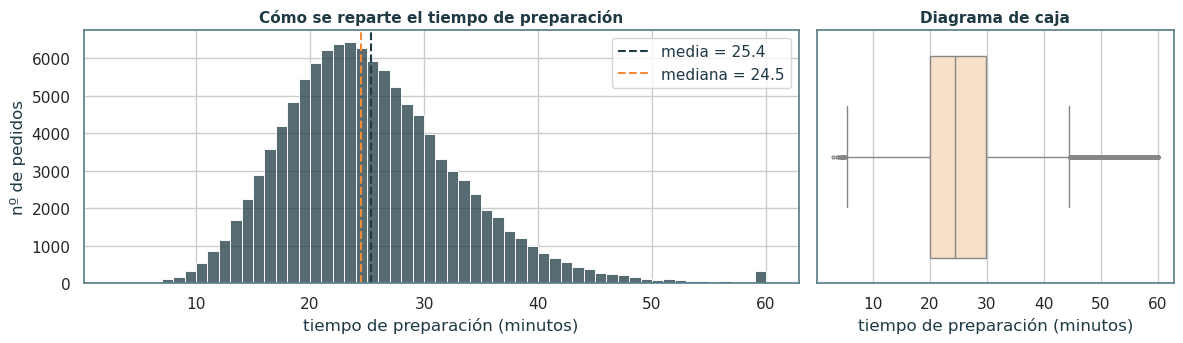

In [5]:
# Tabla resumen del objetivo
resumen_objetivo = resumen_numerico(pedidos, [OBJETIVO])
display(resumen_objetivo)

limite_bajo, limite_alto = limites_iqr(pedidos[OBJETIVO])
print(f"Un pedido se considera atípico si tarda más de {limite_alto:.1f} min (regla del IQR).")
print(f"Pedidos en el tope de {TIEMPO_MAX} min: {int((pedidos[OBJETIVO] == TIEMPO_MAX).sum()):,} "
      f"({(pedidos[OBJETIVO] == TIEMPO_MAX).mean():.2%}) | en el mínimo de {TIEMPO_MIN} min: {int((pedidos[OBJETIVO] == TIEMPO_MIN).sum()):,}")
print("Percentiles (el 90 % de los pedidos tarda menos de…):")
display(pedidos[OBJETIVO].quantile([0.05, 0.25, 0.5, 0.75, 0.90, 0.95, 0.99]).to_frame("minutos").T)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [2, 1]})
sns.histplot(pedidos[OBJETIVO], bins=57, color=AZUL, ax=axes[0])
axes[0].axvline(pedidos[OBJETIVO].mean(), color=AZUL, linestyle="--", label=f"media = {pedidos[OBJETIVO].mean():.1f}")
axes[0].axvline(pedidos[OBJETIVO].median(), color=NARANJA, linestyle="--", label=f"mediana = {pedidos[OBJETIVO].median():.1f}")
axes[0].set(title="Cómo se reparte el tiempo de preparación", xlabel=ETIQUETAS[OBJETIVO], ylabel="nº de pedidos")
axes[0].legend()
sns.boxplot(x=pedidos[OBJETIVO], color=MELOCOTON, fliersize=2, ax=axes[1])
axes[1].set(title="Diagrama de caja", xlabel=ETIQUETAS[OBJETIVO])
fig.tight_layout()
plt.show()

**Cómo leerlo:** la media (línea azul) queda un poco a la derecha de la mediana (línea naranja) porque el histograma tiene **una cola hacia la derecha**: hay pocos pedidos muy lentos que tiran de la media hacia arriba. Es lo normal en tiempos: un pedido no puede tardar menos de 0 minutos, pero sí puede tardar muchísimo.

**El tope de 60 minutos:** en el extremo derecho hay una barra aparte, justo en 60: son **303 pedidos (0,27 %)**. Sale mucho más alta de lo que tocaría por la forma de la cola, lo que indica que **60 es un tope**: el sistema no registra más, aunque el pedido tardara más. El mínimo, en cambio, no se acumula (solo 1 pedido en 3 minutos).

**Dato clave para el modelo:** esa cola larga significa que los pedidos muy lentos serán los más difíciles de predecir bien. Por eso, además del error medio (MAE) miraremos el RMSE, que castiga más los fallos grandes.

---
## 3. Variables numéricas del pedido

**Qué hacemos:** miramos cada variable numérica por separado, antes de relacionarla con nada.

**Cómo leer los histogramas:** eje x = valor de la variable; eje y = cuántos pedidos tienen ese valor. Si la variable solo toma unos pocos valores (como el nº de platos), hay **una barra por valor**.

**Qué buscamos:** valores que casi no cambian (aportan poco), colas largas, o acumulaciones raras (por ejemplo, muchísimos ceros).

,count,mean,std,min,25%,50%,75%,max,asimetria,atipicos,% atipicos
n_platos,"112,963.000",3.405,1.590,1.000,2.000,3.000,4.000,8.000,0.598,1770,1.567
num_platos_complejos,"112,963.000",0.832,0.881,0.000,0.000,1.000,1.000,6.000,1.003,5214,4.616
complejidad_pedido,"112,963.000",4.593,1.426,1.000,3.670,4.500,5.500,10.000,0.132,969,0.858
cola_pedidos,"112,963.000",7.728,4.773,0.000,4.000,7.000,11.000,20.000,0.611,0,0.000
cocineros_disponibles,"112,963.000",4.820,1.251,1.000,4.000,5.000,6.000,7.000,-0.176,0,0.000
precipitacion_mm,"112,963.000",2.469,5.033,0.000,0.000,0.000,2.900,38.200,3.066,13544,11.990
hora_dec,"112,963.000",17.214,3.539,10.000,14.080,16.100,20.780,22.980,0.075,0,0.000


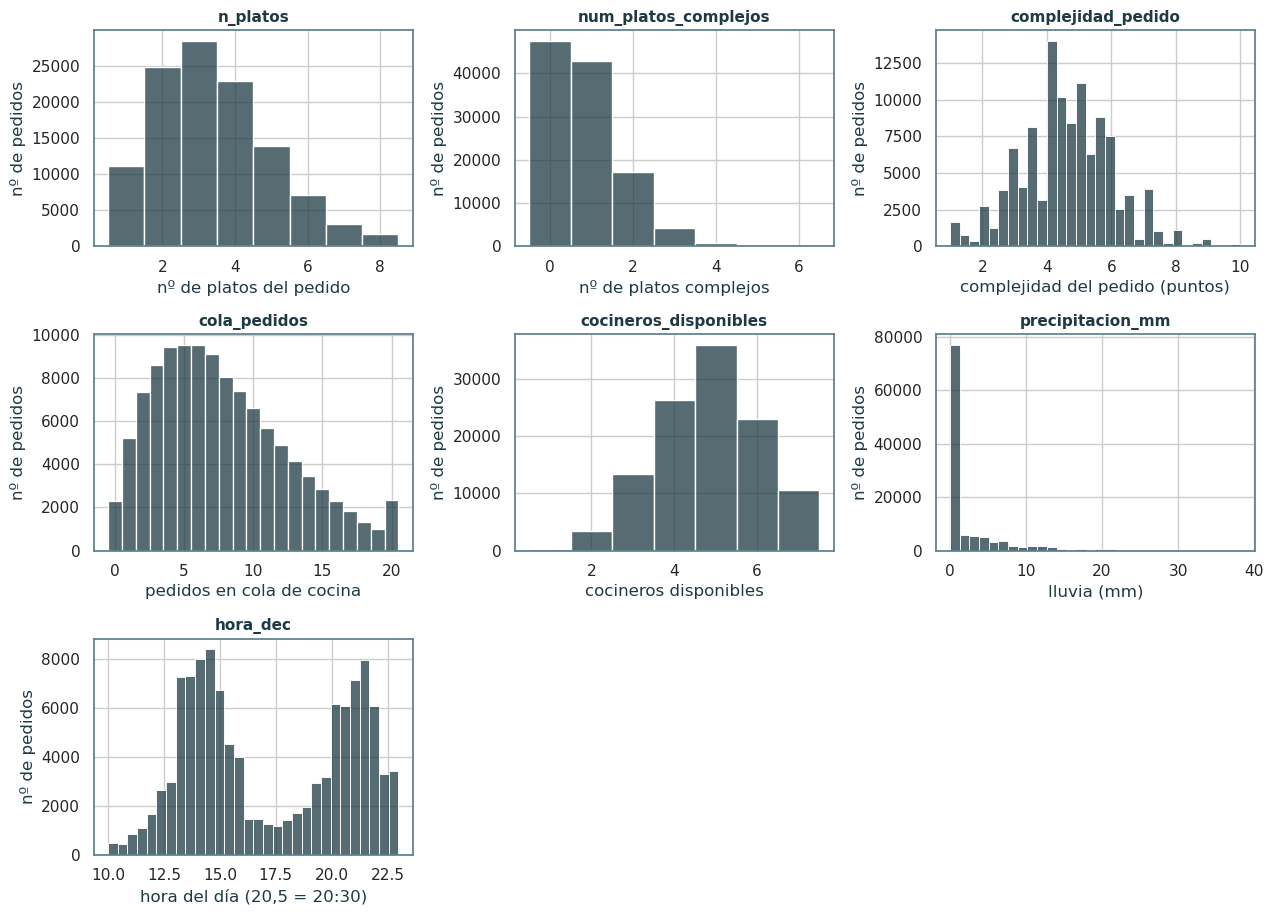

Pedidos en días sin lluvia: 61.0%


In [6]:
# Tabla resumen de las variables numéricas
display(resumen_numerico(pedidos, COLS_NUMERICAS))

# Un histograma por variable
histogramas(pedidos, COLS_NUMERICAS)

# La lluvia tiene muchos ceros: ¿qué parte de los pedidos fue en un día sin lluvia?
print(f"Pedidos en días sin lluvia: {(pedidos['precipitacion_mm'] == 0).mean():.1%}")

**Cómo leer la tabla:** `asimetria` positiva = cola hacia los valores grandes; `atipicos` = cuántos pedidos quedan fuera de los límites del IQR; `% atipicos` = ese número en porcentaje.

**Qué vemos:**
- **`n_platos`:** de 1 a 8 platos; lo más habitual es pedir 2, 3 o 4. **`num_platos_complejos`:** casi siempre 0 o 1 (un 4,6 % de pedidos tiene 3 o más, que la regla del IQR marca como "atípicos").
- **`cola_pedidos`:** de 0 a 20, con la mayoría entre 3 y 10. Ojo a la **última barra (20)**: es más alta que la de 19 (2.332 pedidos frente a 993). Parece que **la cola está recortada en 20**: cualquier cola mayor se registra como 20. Es un tope de los datos, no una cola real de exactamente 20 pedidos.
- **`cocineros_disponibles`:** de 1 a 7, casi siempre 4, 5 o 6. Solo hay 241 pedidos con 1 cocinero, así que ese caso se conoce menos bien que los demás.
- **`precipitacion_mm`:** el **61 % de los pedidos son en días sin lluvia** (el pico del cero) y el resto tiene una cola larga hasta 38 mm. Por eso la asimetría es tan alta (3,07) y casi un 12 % salen como "atípicos": son días de lluvia fuerte, que existen de verdad.
- **`hora_dec`:** **dos picos**, la hora de la comida (13:00 a 15:00) y la de la cena (20:00 a 22:00), con muy pocos pedidos por la mañana y a media tarde.
- **`complejidad_pedido`:** de 1 a 10, con barras en "peine" porque se calcula a partir de platos concretos y toma ciertos valores más que otros.

Todos los valores "atípicos" de estas variables son **posibles** (un pedido de 8 platos o una cola de 20 existen de verdad), no errores: **no hay que eliminarlos**.

---
## 4. Variables de tipo categoría

**Qué hacemos:** `canal`, `prioridad_aux` e `ingrediente_agotado` son categorías (solo toman unas pocas opciones). `dia_semana` también lo tratamos como categoría porque sus valores son días concretos.

**Cómo leer los gráficos:** eje x = cada opción; eje y = cuántos pedidos hay de esa opción. Barras muy desiguales significan que unas opciones son mucho más frecuentes que otras.

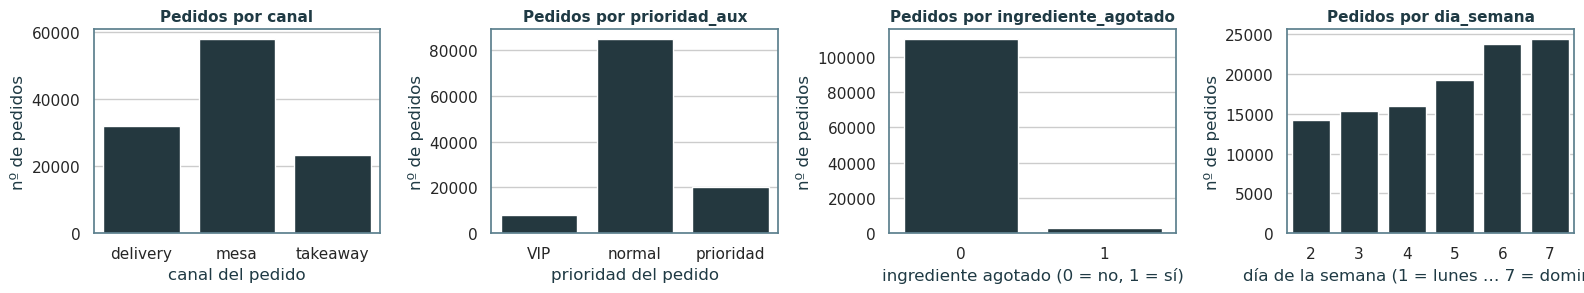


canal:
canal
mesa        51.2 %
delivery    28.2 %
takeaway    20.7 %

prioridad_aux:
prioridad_aux
normal       75.2 %
prioridad    18.0 %
VIP           6.9 %

ingrediente_agotado:
ingrediente_agotado
0    97.3 %
1     2.7 %


In [7]:
barras_conteo(pedidos, COLS_CATEGORICAS)

# También en porcentaje, para tener a mano cuánto pesa cada opción
for col in ["canal", "prioridad_aux", "ingrediente_agotado"]:
    print(f"\n{col}:")
    print((pedidos[col].value_counts(normalize=True) * 100).round(1).astype(str).add(" %").to_string())

**Qué vemos:**
- **`canal`:** la mitad de los pedidos son en mesa (51 %), después delivery (28 %) y takeaway (21 %).
- **`prioridad_aux`:** el 75 % de los pedidos son normales, el 18 % tienen prioridad y el 7 % son VIP.
- **`ingrediente_agotado`:** solo el **2,7 %** de los pedidos (3.074) tuvo algún ingrediente agotado. Es poco frecuente, pero con miles de pedidos todavía hay datos de sobra.
- **`dia_semana`:** el sábado (6) y el domingo (7) tienen bastantes más pedidos que entre semana. El lunes (1) no aparece.

Ninguna opción tiene tan pocos pedidos como para ser poco fiable.

---
## 5. Relación de cada variable con el tiempo de preparación

**Esta es la sección más importante.** Hasta ahora hemos mirado cada variable sola. Ahora vemos **cuáles influyen en el tiempo** y **de qué manera**.

### 5.1 Ranking de correlaciones
Calculamos la correlación de cada variable numérica con el tiempo. Usamos dos tipos:
- **Pearson**: mide si la relación es una **línea recta**.
- **Spearman**: mide si, al subir una variable, el tiempo **tiende a subir** (aunque sea en curva). Si Pearson y Spearman son muy distintas, la relación **no es una línea recta**.

**Cómo leer el gráfico:** eje y = cada variable; eje x = correlación con el tiempo. Barras a la derecha = a más valor, más tiempo; a la izquierda = a más valor, menos tiempo; cerca de 0 = no hay relación en línea recta.

,pearson,spearman
cola_pedidos,0.627,0.631
n_platos,0.511,0.528
num_platos_complejos,0.437,0.453
dia_semana,0.314,0.324
complejidad_pedido,0.281,0.298
ingrediente_agotado,0.100,0.102
precipitacion_mm,0.051,0.078
hora_dec,0.037,0.045
cocineros_disponibles,-0.026,0.039


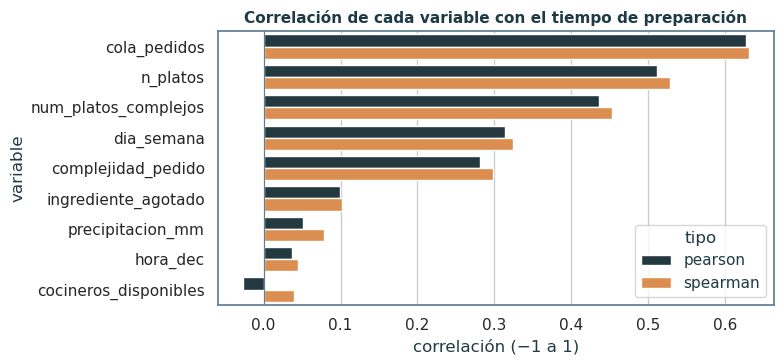

In [8]:
# Correlación de cada variable numérica con el tiempo de preparación (de la mayor a la menor)
variables_corr = COLS_NUMERICAS + ["ingrediente_agotado", "dia_semana"]
datos_corr = pedidos[variables_corr + [OBJETIVO]].astype(float)
ranking = pd.DataFrame({
    "pearson": datos_corr.corr(method="pearson")[OBJETIVO].drop(OBJETIVO),
    "spearman": datos_corr.corr(method="spearman")[OBJETIVO].drop(OBJETIVO),
}).sort_values("pearson", ascending=False)
display(ranking)

fig, ax = plt.subplots(figsize=(8, 3.8))
ranking_largo = ranking.reset_index().melt(id_vars="index", var_name="tipo", value_name="correlación")
sns.barplot(data=ranking_largo, y="index", x="correlación", hue="tipo", palette=[AZUL, NARANJA], ax=ax)
ax.axvline(0, color=GRIS_AZULADO, linewidth=0.8)
ax.set(title="Correlación de cada variable con el tiempo de preparación", xlabel="correlación (−1 a 1)", ylabel="variable")
fig.tight_layout()
plt.show()

**Cómo leerlo:**
- **`cola_pedidos` (0,63)** es la que más se relaciona con el tiempo, seguida de **`n_platos` (0,51)**, **`num_platos_complejos` (0,44)**, **`dia_semana` (0,31)** y **`complejidad_pedido` (0,28)**.
- **`ingrediente_agotado` (0,10)**, **`precipitacion_mm` (0,05)** y **`hora_dec` (0,04)** casi no tienen relación **en línea recta**, y **`cocineros_disponibles` (−0,03)** tampoco.
- Pearson y Spearman dan casi lo mismo, así que en general las relaciones son rectas o crecientes, **salvo** en `cocineros_disponibles` y `hora_dec`.

Ojo: una correlación baja **no significa** que la variable no sirva; solo dice que **no hay relación en línea recta**. Por eso en la siguiente subsección dibujamos cada relación.

### 5.2 El tiempo medio según el valor de cada variable numérica
Para cada variable dibujamos una **curva**:
- **Eje x:** el valor de la variable (si tiene muchos valores, se agrupan en 12 tramos con la misma cantidad de pedidos).
- **Eje y:** el tiempo de preparación medio de los pedidos con ese valor (línea azul).
- **Banda naranja clara:** dónde está la mitad central de los pedidos. Si la banda es muy ancha, hay mucha variación que esa variable sola **no** explica.

**Qué buscamos:** si la curva es una **recta**, una curva, tiene un **codo** o es **plana** (sin efecto).

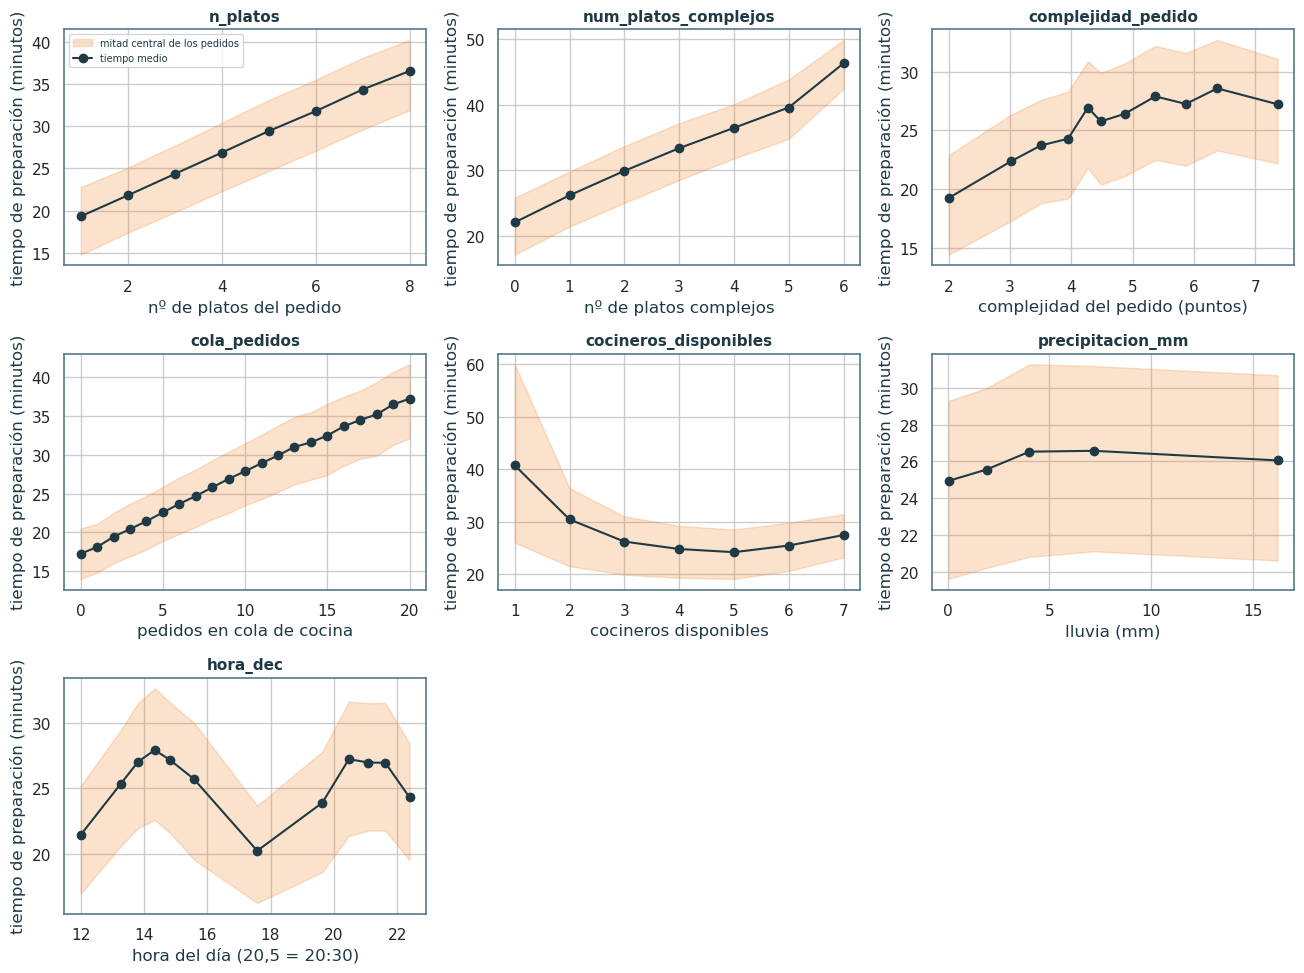

In [9]:
curva_tiempo_medio(pedidos, COLS_NUMERICAS)

**Qué vemos:**
- **`n_platos`:** una **recta casi perfecta**: cada plato más añade unos **2,5 minutos** (de 19 min con 1 plato a 37 min con 8).
- **`num_platos_complejos`:** otra recta: cada plato complejo añade unos **3,5 a 4 minutos** (de 22 min con ninguno a 46 con 6).
- **`cola_pedidos`:** también recta, casi **1 minuto por cada pedido en cola** (de 17 min con la cocina vacía a 37 min con 20 pedidos esperando).
- **`complejidad_pedido`:** sube hasta unos 5 puntos y **luego se aplana**: no es una recta.
- **`cocineros_disponibles`:** **no es una recta, es una curva en forma de "U"**. Con 1 cocinero el tiempo medio es de 41 min, baja hasta unos 24 min con 5 cocineros y **vuelve a subir** hasta 27 min con 7. Un resultado contraintuitivo que explicamos en la sección 8.
- **`precipitacion_mm`:** efecto **pequeño**: de 25 min sin lluvia a unos 26,5 min con lluvia, y se queda plano a partir de unos 5 mm.
- **`hora_dec`:** **dos picos**, a mediodía y por la noche, que coinciden con las horas con más pedidos (ver sección 6). Por eso su correlación en línea recta era casi cero, aunque la relación es fuerte. (Aquí la hora se agrupa en solo 12 tramos; en la sección 6 se ve hora por hora.)

La banda naranja es ancha en todas: ninguna variable sola explica el tiempo; hay que **combinarlas**.

### 5.3 El tiempo según cada categoría
**Tiempo medio** (barras, con el número encima) y **cómo se reparten los tiempos** (cajas). Eje x = opción; eje y = minutos.

pedidos  tiempo_medio  tiempo_mediana  \
canal               delivery     31831        28.057          27.200   
                    mesa         57802        24.039          23.200   
                    takeaway     23330        24.932          24.000   
prioridad_aux       VIP           7769        22.032          21.200   
                    normal       84896        26.094          25.200   
                    prioridad    20298        23.537          22.600   
ingrediente_agotado 0           109889        25.225          24.400   
                    1             3074        30.002          29.400   

                               desviacion  
canal               delivery        7.770  
                    mesa            7.505  
                    takeaway        7.521  
prioridad_aux       VIP             7.397  
                    normal          7.686  
                    prioridad       7.669  
ingrediente_agotado 0               7.740  
                    1               7.709

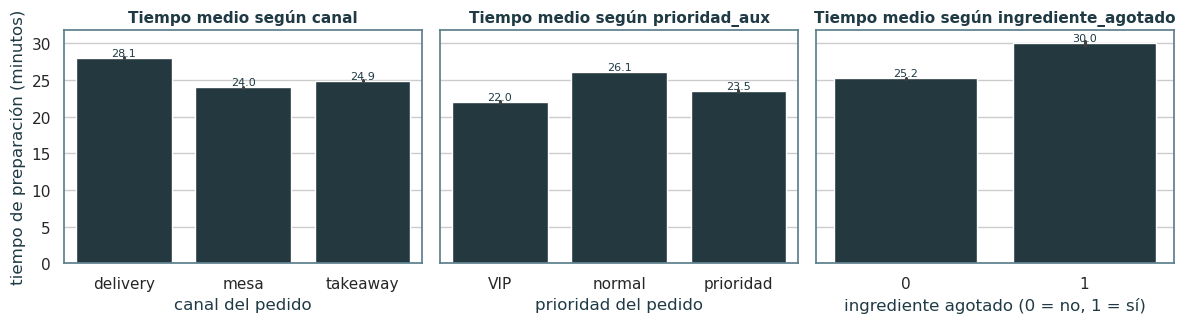

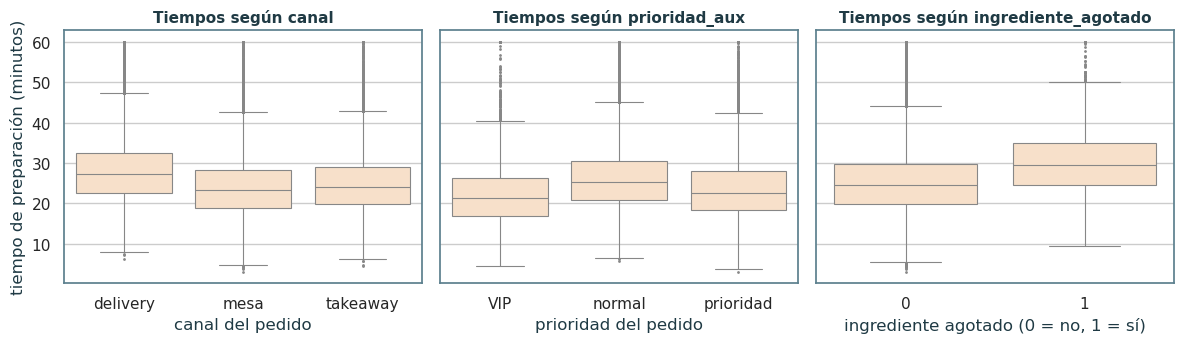

In [10]:
columnas_cat = ["canal", "prioridad_aux", "ingrediente_agotado"]
display(pd.concat({c: tabla_por_grupo(pedidos, c) for c in columnas_cat}))
barras_tiempo_medio(pedidos, columnas_cat)
cajas_tiempo(pedidos, columnas_cat)

**Cómo leerlo:**
- **`canal`:** el **delivery** tarda de media unos 28 min, el **takeaway** 25 y la **mesa** 24: el delivery añade unos **4 minutos** respecto a mesa.
- **`prioridad_aux`:** los pedidos **VIP** tardan 22 min, los de **prioridad** 23,5 y los **normales** 26: un pedido normal tarda unos **4 minutos más** que un VIP.
- **`ingrediente_agotado`:** con algún ingrediente agotado se tarda 30 min de media frente a 25,2: **casi 5 minutos más**.
- Las cajas **se solapan mucho** (dentro de cada opción los tiempos se reparten de forma parecida, con una desviación de unos 7,5 min). Es decir: cada categoría **desplaza** el tiempo unos 4 o 5 minutos, pero **no basta por sí sola** para predecirlo.

---
## 6. El tiempo: hora, día de la semana y evolución

**Qué hacemos:** comprobamos si el tiempo de preparación cambia a lo largo del día, de la semana y de los años. Esto importa por dos motivos:
1. Si cambia con la hora o el día, el modelo necesita esas variables.
2. Si **cambia con el paso de los años** (tendencia), entrenar con pedidos antiguos y probar con recientes será más difícil: lo veremos en la sección 9.

**Cómo leer los gráficos:**
- **Pedidos por hora** (izquierda): eje x = hora; eje y = cuántos pedidos entran. Los picos son las horas de más trabajo.
- **Tiempo medio por hora** (derecha): eje x = hora; eje y = minutos de media.

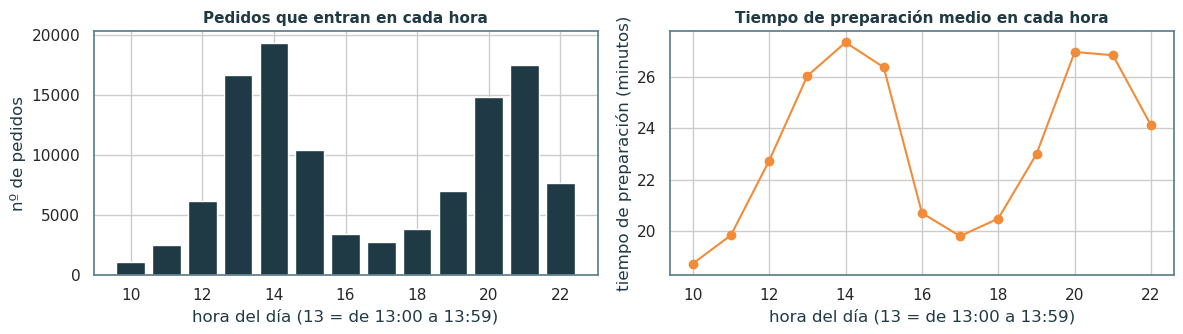

hora_dec,10,11,12,13,14,15,16,17,18,19,20,21,22
pedidos,"1,033.000","2,454.000","6,141.000","16,688.000","19,364.000","10,405.000","3,374.000","2,743.000","3,833.000","6,998.000","14,817.000","17,484.000","7,629.000"
tiempo_medio,18.703,19.823,22.738,26.059,27.369,26.392,20.685,19.784,20.471,22.999,26.996,26.865,24.116


In [11]:
por_hora = pedidos.groupby(pedidos["hora_dec"].astype(int)).agg(pedidos=(OBJETIVO, "size"), tiempo_medio=(OBJETIVO, "mean"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].bar(por_hora.index, por_hora["pedidos"], color=AZUL)
axes[0].set(title="Pedidos que entran en cada hora", xlabel="hora del día (13 = de 13:00 a 13:59)", ylabel="nº de pedidos")
axes[1].plot(por_hora.index, por_hora["tiempo_medio"], marker="o", color=NARANJA)
axes[1].set(title="Tiempo de preparación medio en cada hora", xlabel="hora del día (13 = de 13:00 a 13:59)", ylabel=ETIQUETAS[OBJETIVO])
fig.tight_layout()
plt.show()
display(por_hora.T)

### Día de la semana
**Cómo leer los gráficos:** eje x = día de la semana (1 = lunes … 7 = domingo; el 1 no aparece porque no hay pedidos ese día). Izquierda: cuántos pedidos hay cada día. Derecha: tiempo medio de preparación.

,pedidos,tiempo_medio,tiempo_mediana,desviacion,pedidos_por_dia_abierto
dia_semana,,,,,
2,14235,22.378,21.900,6.328,90.669
3,15337,22.606,22.000,6.483,97.688
4,15958,23.130,22.500,6.771,102.295
5,19227,24.129,23.400,7.158,123.250
6,23779,28.169,27.400,7.973,152.429
7,24427,28.497,27.800,8.121,155.586


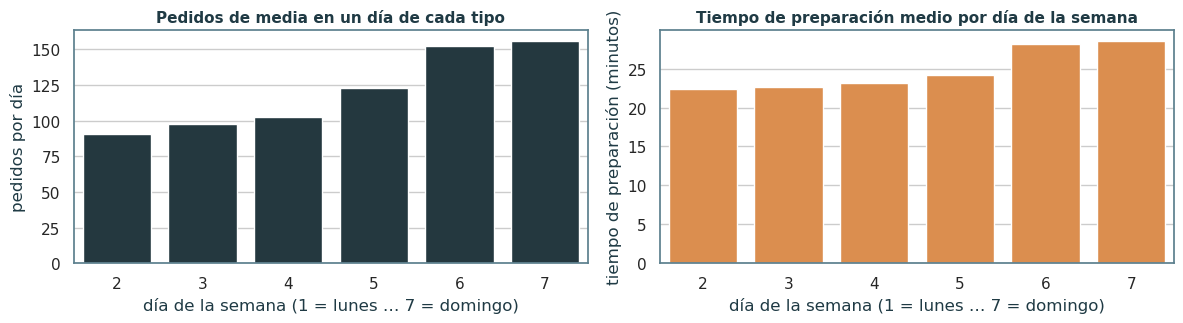

Días del calendario: 1096 | con pedidos: 939 | sin pedidos: 157
Días de la semana de los días sin pedidos (0 = lunes): [0]
¿Todos los días sin pedidos son lunes? True


In [12]:
por_dia = tabla_por_grupo(pedidos, "dia_semana")
dias_abiertos = pedidos["fecha"].groupby(pedidos["dia_semana"]).nunique()
por_dia["pedidos_por_dia_abierto"] = por_dia["pedidos"] / dias_abiertos      # pedidos de media en un día de ese tipo
display(por_dia)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
sns.barplot(x=por_dia.index.astype(str), y=por_dia["pedidos_por_dia_abierto"], color=AZUL, ax=axes[0])
axes[0].set(title="Pedidos de media en un día de cada tipo", xlabel=ETIQUETAS["dia_semana"], ylabel="pedidos por día")
sns.barplot(x=por_dia.index.astype(str), y=por_dia["tiempo_medio"], color=NARANJA, ax=axes[1])
axes[1].set(title="Tiempo de preparación medio por día de la semana", xlabel=ETIQUETAS["dia_semana"], ylabel=ETIQUETAS[OBJETIVO])
fig.tight_layout()
plt.show()

# ¿Cierra el restaurante los lunes? Comparamos los días del calendario con los días con pedidos
todos_los_dias = pd.date_range(pedidos["fecha"].min(), pedidos["fecha"].max(), freq="D")
sin_pedidos = todos_los_dias.difference(pd.DatetimeIndex(pedidos["fecha"].unique()))
print(f"Días del calendario: {len(todos_los_dias)} | con pedidos: {pedidos['fecha'].nunique()} | sin pedidos: {len(sin_pedidos)}")
print("Días de la semana de los días sin pedidos (0 = lunes):", sorted(set(sin_pedidos.dayofweek)))
print(f"¿Todos los días sin pedidos son lunes? {bool((sin_pedidos.dayofweek == 0).all())}")

### Evolución a lo largo de los años
**Cómo leer los gráficos:** eje x = mes; eje y = número de pedidos (izquierda) o tiempo medio (derecha). Buscamos **tendencia** (la línea sube o baja a lo largo de los años) y **estacionalidad** (se repite cada año, por ejemplo más en verano).

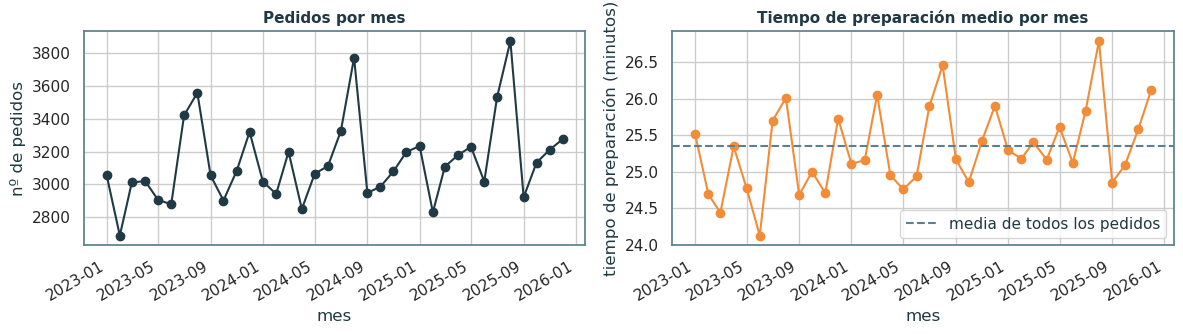

Por año:


,pedidos,tiempo_medio,tiempo_mediana,desviacion
anio,,,,
2023,36909,25.095,24.300,7.673
2024,37498,25.421,24.500,7.781
2025,38556,25.540,24.700,7.867


Tiempo medio por mes del año: mínimo 24.7 min (mes 6), máximo 26.4 min (mes 8)


In [13]:
por_mes = pedidos.groupby(pedidos["fecha"].dt.to_period("M")).agg(pedidos=(OBJETIVO, "size"), tiempo_medio=(OBJETIVO, "mean"))
por_mes.index = por_mes.index.to_timestamp()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(por_mes.index, por_mes["pedidos"], marker="o", color=AZUL)
axes[0].set(title="Pedidos por mes", xlabel="mes", ylabel="nº de pedidos")
axes[1].plot(por_mes.index, por_mes["tiempo_medio"], marker="o", color=NARANJA)
axes[1].axhline(pedidos[OBJETIVO].mean(), color=GRIS_AZULADO, linestyle="--", label="media de todos los pedidos")
axes[1].set(title="Tiempo de preparación medio por mes", xlabel="mes", ylabel=ETIQUETAS[OBJETIVO])
axes[1].legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

# Resumen por año y por mes del año (para comprobar tendencia y estacionalidad con números)
por_anio = tabla_por_grupo(pedidos.assign(anio=pedidos["fecha"].dt.year), "anio")
print("Por año:")
display(por_anio)
variacion_mensual = (pedidos.groupby(pedidos["fecha"].dt.month)[OBJETIVO].mean())
print(f"Tiempo medio por mes del año: mínimo {variacion_mensual.min():.1f} min (mes {variacion_mensual.idxmin()}), "
      f"máximo {variacion_mensual.max():.1f} min (mes {variacion_mensual.idxmax()})")

**Qué vemos:**
- **Hora:** los pedidos se concentran en la **comida (13:00 a 15:00)** y la **cena (20:00 a 22:00)**, y el tiempo de preparación **sigue esos mismos picos**: unos 19 min a las 10 de la mañana, 27 a las 14:00, 20 sobre las 17:00 y 27 a las 20:00. Es la misma historia que la cola: **más trabajo, más espera**.
- **Día de la semana:** de martes a viernes se tarda entre 22 y 24 min de media; **sábado y domingo, unos 28**. Esos días también hay más pedidos (de unos 91 a 156 por día de media, del martes al domingo).
- **Lunes cerrado:** hay 157 días del calendario sin pedidos y **todos son lunes**. El restaurante no abre los lunes, así que `dia_semana` solo toma los valores 2 a 7.
- **Tendencia:** casi no hay. El tiempo medio pasa de **25,1 min (2023)** a **25,4 (2024)** y **25,5 (2025)**: una subida pequeña, de unos 0,4 min en dos años.
- **Estacionalidad:** suave. El mes más rápido (junio) tarda 24,7 min y el más lento (agosto), 26,4 min; agosto además tiene bastantes más pedidos.

La conclusión es que el tiempo es **bastante estable** a lo largo de los años, así que entrenar con el pasado y probar con el futuro es una prueba justa (aunque con un pequeño desfase que revisamos en la sección 9).

---
## 7. Relaciones entre las propias variables

**Qué hacemos:** hasta ahora comparamos cada variable con el tiempo. Ahora comparamos **las variables entre sí**.

**Por qué importa:** si dos variables van casi siempre juntas (por ejemplo, más platos → más platos complejos), el modelo recibe **información repetida**. Los modelos de tipo lineal se confunden con esto (no saben cuál de las dos es "responsable"), y además es más difícil explicar el resultado.

**Cómo leer el mapa de calor:** cada casilla es la correlación entre la variable de la fila y la de la columna. **Naranja** = suben juntas; **azul** = una sube y la otra baja; **blanco** = sin relación. El número dentro es la correlación.

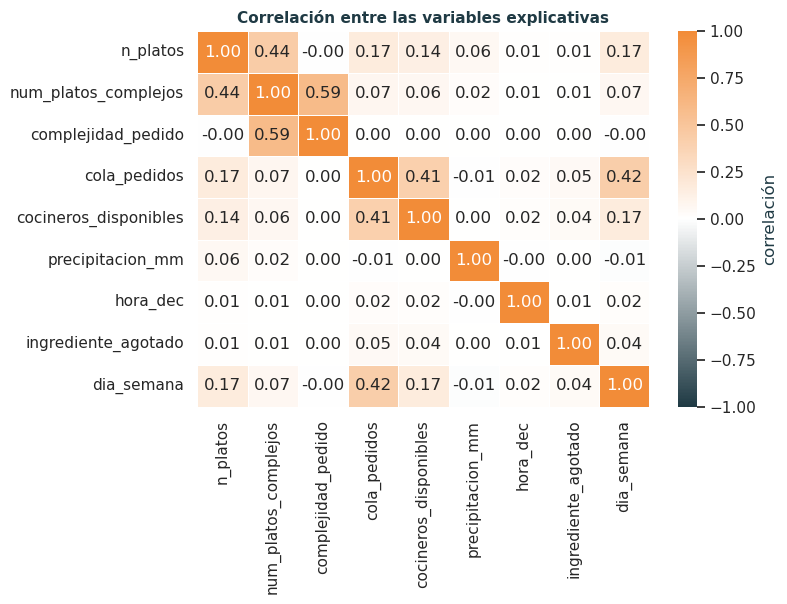

correlación
num_platos_complejos  complejidad_pedido           0.593
n_platos              num_platos_complejos         0.440
cola_pedidos          dia_semana                   0.422
                      cocineros_disponibles        0.407
n_platos              cola_pedidos                 0.171
cocineros_disponibles dia_semana                   0.171

In [14]:
explicativas_num = COLS_NUMERICAS + ["ingrediente_agotado", "dia_semana"]
corr = pedidos[explicativas_num].astype(float).corr()

fig, ax = plt.subplots(figsize=(8, 6.2))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=CMAP_DIV, vmin=-1, vmax=1, linewidths=0.5, ax=ax,
            cbar_kws={"label": "correlación"})
ax.set_title("Correlación entre las variables explicativas")
fig.tight_layout()
plt.show()

# Las parejas más relacionadas (sin contar cada pareja dos veces ni una variable consigo misma)
parejas = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("correlación").to_frame()
parejas["valor_absoluto"] = parejas["correlación"].abs()
display(parejas.sort_values("valor_absoluto", ascending=False).head(6)[["correlación"]])

**Qué vemos:**
- La pareja más relacionada es **`num_platos_complejos` y `complejidad_pedido` (0,59)**: es lógico, porque la complejidad del pedido se calcula en parte a partir de los platos complejos.
- Después: `n_platos` con `num_platos_complejos` (0,44), `cola_pedidos` con `dia_semana` (0,42) y `cola_pedidos` con `cocineros_disponibles` (0,41). El fin de semana hay más cola (10,2 pedidos de media frente a 5,9 entre semana).
- **Ninguna pareja llega a 0,8**: no hay variables casi duplicadas. Podemos **conservarlas todas**; `complejidad_pedido` y `num_platos_complejos` se parecen algo, pero cada una aporta información propia.
- Sí hay una relación importante: **`cola_pedidos` y `cocineros_disponibles` van juntas (0,41)**. Es la clave de la sección siguiente.

---
## 8. Pedidos en cola y cocineros

**Qué hacemos:** en la sección 5 vimos algo raro: el tiempo **sube con la cola de pedidos** (lógico) pero **no baja de forma clara al haber más cocineros**. ¿Por qué? Sospechamos que **los cocineros se ponen donde hay más trabajo**: cuando la cocina está llena, hay más cocineros. Así "más cocineros" y "más cola" **van juntos** y se tapan el efecto uno al otro. Que el efecto de una variable **dependa de otra** se llama **interacción**.

**Cómo comprobarlo:** un **mapa de calor**. Eje x = pedidos en cola; eje y = cocineros; el **color** es el tiempo medio de preparación (más oscuro = más minutos). Se ocultan las combinaciones con muy pocos pedidos porque su media no sería fiable.

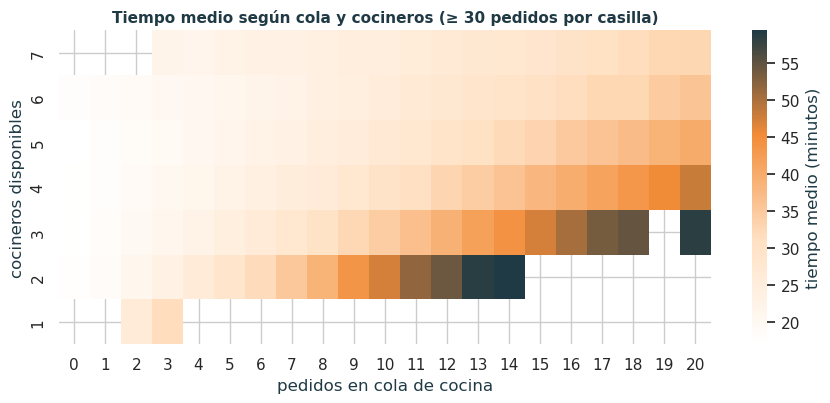

Correlación entre cola y cocineros: 0.41


cocineros_disponibles,1,2,3,4,5,6,7
cola_media,4.967,5.135,5.576,6.308,7.161,9.592,12.764


cocineros_disponibles,1,2,3,4,5,6,7
count,1.000,4.000,36.000,188.000,543.000,782.000,778.000
mean,60.000,60.000,58.433,47.996,40.187,35.840,32.903


In [15]:
# Tabla cola x cocineros con el tiempo medio y el nº de pedidos de cada combinación
tabla_media = pedidos.pivot_table(index="cocineros_disponibles", columns="cola_pedidos", values=OBJETIVO, aggfunc="mean", observed=True)
tabla_n = pedidos.pivot_table(index="cocineros_disponibles", columns="cola_pedidos", values=OBJETIVO, aggfunc="size", observed=True)
tabla_media = tabla_media.where(tabla_n >= MIN_PEDIDOS_CELDA)            # ocultamos combinaciones poco fiables

fig, ax = plt.subplots(figsize=(9, 4.2))
sns.heatmap(tabla_media.sort_index(ascending=False), cmap=CMAP_SEC, ax=ax, annot=False,
            cbar_kws={"label": "tiempo medio (minutos)"})
ax.set(title=f"Tiempo medio según cola y cocineros (≥ {MIN_PEDIDOS_CELDA} pedidos por casilla)",
       xlabel=ETIQUETAS["cola_pedidos"], ylabel=ETIQUETAS["cocineros_disponibles"])
fig.tight_layout()
plt.show()

# ¿Los cocineros se ajustan a la cola? Correlación entre ambas y cola media según el nº de cocineros
print(f"Correlación entre cola y cocineros: {pedidos['cola_pedidos'].astype(float).corr(pedidos['cocineros_disponibles'].astype(float)):.2f}")
display(pedidos.groupby("cocineros_disponibles")["cola_pedidos"].mean().to_frame("cola_media").T)

# Tiempo medio con la cola al máximo (20 pedidos) según los cocineros: misma cola, distinta plantilla
display(pedidos[pedidos["cola_pedidos"] == 20].groupby("cocineros_disponibles")[OBJETIVO].agg(["count", "mean"]).T)

**Qué vemos:**
- **Los cocineros se ajustan a la demanda:** con 1 cocinero la cola media es de unos 5 pedidos y con 7 cocineros de unos 13. Por eso "más cocineros" aparece junto a "más cola", y el efecto de tener más gente **queda tapado** por el de tener más trabajo. Esto explica la curva en "U" de `cocineros_disponibles`.
- **El mapa de calor lo confirma:** con la misma cola de 20 pedidos, **3 cocineros** llevan el tiempo medio a unos **58 min** (casi el tope de 60), **5 cocineros** a unos 40 min y **7 cocineros** a unos 33 min. Cada cocinero extra **sí** reduce el tiempo cuando la cola es la misma.
- Con muchos pedidos en cola y pocos cocineros, el tiempo **toca el tope de 60 minutos**. Es un valor "recortado": el tiempo real podría haber sido mayor.

**Qué implica para el modelo:** `cola_pedidos` y `cocineros_disponibles` **no actúan por separado**: su efecto depende de la combinación de las dos. Un modelo lineal sencillo no puede captar eso (suma los efectos de cada variable por separado); un modelo basado en **árboles** sí, porque decide por tramos y combina variables. No creamos ninguna variable nueva: usaremos las dos tal cual y dejaremos que el modelo encuentre la combinación.

---
## 9. Separar entrenamiento y prueba, y línea base

### 9.1 Por qué separar por fecha y no al azar
Para saber si un modelo funciona hay que **examinarlo con pedidos que no ha visto**. Se suele separar al azar (*train_test_split*), pero aquí **no es lo más adecuado**:
- En la vida real el modelo se usará **para predecir pedidos futuros**. Si mezclamos al azar, el modelo entrenaría con pedidos de, por ejemplo, el martes y se examinaría con pedidos del mismo martes: ya "conoce" ese momento y el examen sale demasiado fácil.
- Separando por fecha, entrenamos con el **pasado** (el 80 % más antiguo) y probamos con el **futuro** (el 20 % más reciente), igual que pasará de verdad.

**Qué comprobamos aquí:** que las dos partes se parecen (si no, el examen sería injusto) y cuánto vale la predicción más simple.

### 9.2 La línea base
Antes de entrenar nada, calculamos qué error cometeríamos con la predicción **más simple posible: decir siempre la media de los tiempos de entrenamiento**. Un modelo solo es útil si **mejora claramente** ese resultado.

**Cómo leer el gráfico:** eje x = minutos; eje y = proporción de pedidos (la densidad permite comparar dos partes de distinto tamaño). Si las dos formas se solapan, las partes se parecen.

Entrenamiento: 90,300 pedidos (01-01-2023 → 04-06-2025)
Prueba:        22,663 pedidos (05-06-2025 → 31-12-2025)
OK · todo el entrenamiento es anterior a la prueba (sin solapar días)


,count,mean,std,min,25%,50%,75%,max
entrenamiento,"90,300.000",25.270,7.715,3.000,19.900,24.400,29.700,60.000
prueba,"22,663.000",25.696,8.013,4.400,20.100,24.800,30.200,60.000


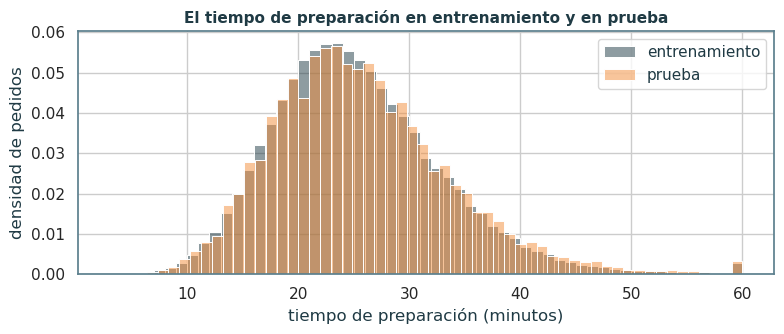

,entrenamiento,prueba,diferencia_%
n_platos,3.408,3.394,-0.424
num_platos_complejos,0.832,0.831,-0.170
complejidad_pedido,4.590,4.603,0.278
cola_pedidos,7.647,8.051,5.283
cocineros_disponibles,4.821,4.814,-0.152
precipitacion_mm,2.533,2.215,-12.584
hora_dec,17.213,17.220,0.042


In [16]:
corte = fecha_de_corte(pedidos)
entrenamiento = pedidos[pedidos["fecha"] < corte]
prueba = pedidos[pedidos["fecha"] >= corte]

print(f"Entrenamiento: {len(entrenamiento):,} pedidos ({entrenamiento['fecha'].min():%d-%m-%Y} → {entrenamiento['fecha'].max():%d-%m-%Y})")
print(f"Prueba:        {len(prueba):,} pedidos ({prueba['fecha'].min():%d-%m-%Y} → {prueba['fecha'].max():%d-%m-%Y})")
validar(entrenamiento["fecha"].max() < prueba["fecha"].min(), "todo el entrenamiento es anterior a la prueba (sin solapar días)")

# ¿Se parecen las dos partes?
comparar = pd.DataFrame({"entrenamiento": entrenamiento[OBJETIVO].describe(), "prueba": prueba[OBJETIVO].describe()})
display(comparar.T)

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(entrenamiento[OBJETIVO], bins=57, stat="density", color=AZUL, alpha=0.5, label="entrenamiento", ax=ax)
sns.histplot(prueba[OBJETIVO], bins=57, stat="density", color=NARANJA, alpha=0.5, label="prueba", ax=ax)
ax.set(title="El tiempo de preparación en entrenamiento y en prueba", xlabel=ETIQUETAS[OBJETIVO], ylabel="densidad de pedidos")
ax.legend()
fig.tight_layout()
plt.show()

# ¿Y las variables explicativas? Media de cada una en las dos partes
medias = pd.DataFrame({"entrenamiento": entrenamiento[COLS_NUMERICAS].astype(float).mean(),
                       "prueba": prueba[COLS_NUMERICAS].astype(float).mean()})
medias["diferencia_%"] = (medias["prueba"] / medias["entrenamiento"] - 1) * 100
display(medias)

In [17]:
# LÍNEA BASE: predecir SIEMPRE la media del entrenamiento (y, para comparar, la mediana)
def errores(reales: pd.Series, predichos: float) -> dict[str, float]:
    """Error de una predicción constante: MAE (media de |error|), RMSE (castiga más los fallos grandes) y R²."""
    error = reales - predichos
    return {"MAE (min)": error.abs().mean(),
            "RMSE (min)": float(np.sqrt((error ** 2).mean())),
            "R²": 1 - (error ** 2).sum() / ((reales - reales.mean()) ** 2).sum()}

linea_base = pd.DataFrame({
    "siempre la media": errores(prueba[OBJETIVO], entrenamiento[OBJETIVO].mean()),
    "siempre la mediana": errores(prueba[OBJETIVO], entrenamiento[OBJETIVO].median()),
}).T
display(linea_base)
print(f"Predecir siempre {entrenamiento[OBJETIVO].mean():.1f} minutos nos equivocaría de media en {linea_base.loc['siempre la media', 'MAE (min)']:.1f} minutos.")
print("Cualquier modelo tiene que bajar claramente de ese MAE y de ese RMSE (y subir el R² por encima de 0).")

,MAE (min),RMSE (min),R²
siempre la media,6.183,8.024,-0.003
siempre la mediana,6.176,8.117,-0.026


Predecir siempre 25.3 minutos nos equivocaría de media en 6.2 minutos.
Cualquier modelo tiene que bajar claramente de ese MAE y de ese RMSE (y subir el R² por encima de 0).


**Qué vemos:**
- Se entrena con el **80 % más antiguo** (90.300 pedidos, hasta el 04-06-2025) y se prueba con el **20 % más reciente** (22.663 pedidos, desde el 05-06-2025). Ningún día está en las dos partes.
- Las dos partes se parecen mucho: tiempo medio de **25,3 min** en entrenamiento y **25,7 min** en prueba, con formas casi iguales en el histograma. La prueba es algo más dura (más cola de media, +5 %; y algo más de variación).
- La parte de prueba solo contiene **de junio a diciembre**, así que no incluye los meses de enero a mayo. Lo tendremos en cuenta al interpretar los resultados.
- **Línea base:** decir siempre "25,3 minutos" falla de media en **6,2 min (MAE)**, con un RMSE de **8,0 min**. El R² es ≈ 0 por definición: decir siempre la media no explica nada de las diferencias entre pedidos.

**Esa es la referencia que el modelo del siguiente notebook debe superar con claridad.**

---
## 10. Conclusiones

### 10.1 Qué hemos aprendido
- **Los datos son de fiar:** 112.963 pedidos, sin vacíos ni duplicados, con todas las comprobaciones de coherencia cumplidas.
- **El tiempo de preparación** va de 3 a 60 minutos, con una media de 25,4 y una cola larga hacia los pedidos lentos (el 90 % tarda 35 minutos o menos).
- **El tiempo depende sobre todo de la carga de trabajo:** cuántos platos lleva el pedido (≈ +2,5 min por plato), cuántos son complejos (≈ +3,5 a 4 min cada uno) y cuánta cola hay en la cocina (≈ +1 min por pedido en cola).
- **La cola y los cocineros van juntos:** se ponen más cocineros cuando hay más cola, y por eso el efecto de los cocineros solo se entiende **combinado con la cola** (con la misma cola, más cocineros bajan el tiempo).
- **La hora y el día importan, pero no en línea recta:** hay dos picos (comida y cena) y el fin de semana se tarda unos 4 a 5 minutos más.
- **El canal (delivery), la prioridad (VIP más rápido) y los ingredientes agotados** desplazan el tiempo unos 4 o 5 minutos.
- **El tiempo es estable a lo largo de los años** (25,1 → 25,5 min en tres años), así que separar entrenamiento y prueba por fecha es una prueba justa.

### 10.2 Qué variables usar
| Variable | Relación con el tiempo | Decisión |
|---|---|---|
| `cola_pedidos` | Recta, la más fuerte (r = 0,63) | **Usar** |
| `n_platos` | Recta (r = 0,51) | **Usar** |
| `num_platos_complejos` | Recta (r = 0,44) | **Usar** |
| `complejidad_pedido` | Sube y se aplana (r = 0,28); se parece a `num_platos_complejos` (0,59) | **Usar** (aporta algo propio) |
| `cocineros_disponibles` | En "U" por culpa de la cola; solo se entiende junto a ella | **Usar** (su efecto depende de la cola; mejor con un modelo de árboles) |
| `hora_dec` | Dos picos (comida y cena); casi 0 en línea recta | **Usar** (la forma con dos picos la capta mejor un modelo de árboles) |
| `dia_semana` | Fin de semana ≈ +5 min (r = 0,31) | **Usar** |
| `canal` | Delivery ≈ +4 min respecto a mesa | **Usar** (codificar como 0/1) |
| `prioridad_aux` | VIP ≈ −4 min respecto a normal | **Usar** (codificar como 0/1) |
| `ingrediente_agotado` | ≈ +5 min, pero solo el 2,7 % de los pedidos | **Usar, tras confirmar que se conoce al hacer el pedido** (ver 10.5) |
| `precipitacion_mm` | Efecto pequeño (≈ +1,5 min; r = 0,05) | **Probar:** el modelo dirá si aporta algo |
| `fecha` | Solo sirve para ordenar y separar entrenamiento y prueba | **No usar como variable del modelo** |

No hace falta eliminar ninguna variable por estar duplicada (ninguna pareja llega a 0,8 de correlación) ni quitar valores atípicos de las variables explicativas (son valores reales).

### 10.3 Variables: las que ya tenemos, con un único cambio de formato
Es el **primer modelo** del proyecto y aceptamos que tenga fallos, así que **no creamos variables nuevas** (nada de ratios ni combinaciones): usaremos las columnas tal cual salen del notebook 02. Lo único que hacemos es un cambio de formato necesario:
- `canal` y `prioridad_aux` son texto y se transforman en columnas 0/1 (*one-hot*), porque algunos modelos (como el lineal) solo entienden números. Es la misma información, solo cambia cómo se escribe. Así **todos los modelos se comparan con exactamente los mismos datos**.
- Cualquier mejora posterior (por ejemplo, combinar la cola con los cocineros) queda como **posible mejora futura**, no como parte de este primer modelo.

### 10.4 Pistas para elegir el modelo
- Muchas relaciones son **bastante rectas** (platos, platos complejos, cola), así que un **modelo lineal** sería un buen punto de partida y una **segunda línea base**, fácil de explicar. Para poder usar también `canal` y `prioridad_aux`, se pasan antes a 0/1 (ver 10.3).
- Hay **curvas e interacciones** (hora, cocineros × cola, día) que no hemos convertido en variables nuevas, así que un modelo **basado en árboles** (por ejemplo *Random Forest* o *Gradient Boosting*), que las encuentra por sí solo, probablemente le gane. La comparación real se hace en el notebook del modelo, **registrando cada prueba en MLflow**.
- El tiempo tiene cola larga hacia la derecha: además del MAE, miraremos el **RMSE** para ver cómo se comporta el modelo con los pedidos más lentos.

### 10.5 Cómo evaluar
- **Separación por fecha:** entrenamiento hasta el **04-06-2025** (90.300 pedidos) y prueba desde el **05-06-2025** (22.663 pedidos). Para ajustar parámetros se puede usar, **dentro del entrenamiento**, una validación que respete el orden temporal; la parte de prueba **no se toca** hasta el final.
- **Métricas (en minutos):** MAE, RMSE y R².
- **Línea base a superar:** predecir siempre la media da **MAE ≈ 6,2 min, RMSE ≈ 8,0 min y R² ≈ 0**. Un buen modelo tiene que bajar claramente de esos errores.

### 10.6 Cuidados y limitaciones
- **Tope de tiempo en 60 minutos** (303 pedidos): son pedidos "recortados", el tiempo real pudo ser mayor. Y **tope de cola en 20** (más de 2.300 pedidos). Lo diremos al interpretar los resultados.
- **`ingrediente_agotado`:** hay que **confirmar con el equipo cuándo se registra**. Si se sabe al entrar el pedido, es una variable válida; si solo se conoce una vez empezada la preparación, sería **fuga de información** y habría que quitarla.
- **Supuesto de disponibilidad:** damos por hecho que `cola_pedidos` y `cocineros_disponibles` se conocen en el momento en que entra el pedido.
- **Lunes cerrado:** el modelo no tiene información de lunes, así que no debe usarse para predecir en lunes.
- **La prueba solo cubre de junio a diciembre.** Los meses de enero a mayo no se evalúan; hay una pequeña tendencia al alza y una estacionalidad suave.
- **Datos sintéticos:** las relaciones son más limpias (más rectas y estables) que en un restaurante real. Cualquier resultado del modelo será **más optimista** de lo que se esperaría en la realidad; hay que decirlo en el informe.

### 10.7 Siguiente paso
Notebook del **modelo de regresión del objetivo 2**: preparar las variables tal cual (con el cambio a 0/1 de `canal` y `prioridad_aux`), comparar el modelo lineal con modelos de árboles, registrar cada prueba en **MLflow** (parámetros, métricas, gráficos y modelo) y comparar con la línea base de esta exploración.
